# Seguridad Integral - Pichincha

Datos mensuales de delitos (enero 2014 - 2026) para la provincia de Pichincha.

- Fuente: `Seguridad_integral_Pichincha.xlsx`
- Hojas: **Provincia** (una fila por mes), **Cantones** (una fila por mes y cantón), Guía y Glosario (metadatos).
- Los CSV ya generados viven en `datos_csv/`.

In [10]:
import pandas as pd
from pathlib import Path

# Base = carpeta del proyecto (el notebook vive en notebooks/)
BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
XLSX = BASE / 'Seguridad_integral_Pichincha.xlsx'
CSV_DIR = BASE / 'datos_csv'
CSV_DIR.mkdir(exist_ok=True)
print('Fuente:', XLSX, XLSX.exists())
print('Hojas:', pd.ExcelFile(XLSX).sheet_names)


Fuente: /home/alejandro/Documentos/Universidad_AlejandroObando/Lectura_Escritura/segundo_parcial/proyecto_SegundoPArcial/Seguridad_integral_Pichincha.xlsx True
Hojas: ['Guía', 'Provincia', 'Cantones', 'Glosario']


In [29]:
cantones =pd.read_csv('../datos_csv/Cantones.csv')
provincia =pd.read_csv('../datos_csv/Provincia.csv')
provincia.columns



Index(['Mes', 'Provincia', 'Homicidios intencionales', 'Femicidios',
       'Denuncias: robo a personas',
       'Denuncias: robo de bienes, accesorios y autopartes de vehículos',
       'Denuncias: robo de motos', 'Denuncias: robo de carros',
       'Denuncias: robo a domicilio', 'Denuncias: robo a unidades económicas'],
      dtype='str')

In [30]:
cantones = cantones.rename(columns={
    "Mes": "mes",
    "Código DPA": "codigo_dpa",
    "Cantón": "canton",
    "Homicidios intencionales": "homicidios",
    "Femicidios": "femicidios",
    "Denuncias: robo a personas": "robo_personas",
    "Denuncias: robo de bienes, accesorios y autopartes de vehículos": "robo_bienes",
    "Denuncias: robo de motos": "robo_motos",
    "Denuncias: robo de carros": "robo_carros",
    "Denuncias: robo a domicilio": "robo_domicilio",
    "Denuncias: robo a unidades económicas": "robo_unidades",
})

provincia = provincia.rename(columns={
    "Homicidios intencionales": "homicidios",
    "Denuncias: robo a personas": "robo_personas",
    "Denuncias: robo de bienes, accesorios y autopartes de vehículos": "robo_bienes",
    "Denuncias: robo de motos": "robo_motos",
    "Denuncias: robo de carros": "robo_carros",
    "Denuncias: robo a domicilio": "robo_domicilio",
    "Denuncias: robo a unidades económicas": "robo_unidades",
})


In [40]:
provincia.columns

Index(['Mes', 'Provincia', 'homicidios', 'Femicidios', 'robo_personas',
       'robo_bienes', 'robo_motos', 'robo_carros', 'robo_domicilio',
       'robo_unidades'],
      dtype='str')

In [38]:
print("VAlores nulos de cantones")
print(cantones.isnull().sum())
print("VAlores nulos de provincias")
print(provincia.isnull().sum())


VAlores nulos de cantones
mes               0
Provincia         0
codigo_dpa        0
canton            0
homicidios        0
femicidios        0
robo_personas     0
robo_bienes       0
robo_motos        0
robo_carros       0
robo_domicilio    0
robo_unidades     0
dtype: int64
VAlores nulos de provincias
Mes               0
Provincia         0
homicidios        0
Femicidios        0
robo_personas     0
robo_bienes       0
robo_motos        0
robo_carros       0
robo_domicilio    0
robo_unidades     0
dtype: int64


In [41]:
cantones=cantones.drop('Provincia', axis=1)
provincia = provincia.drop('Provincia', axis=1)

In [44]:
cantones.columns

Index(['mes', 'codigo_dpa', 'canton', 'homicidios', 'femicidios',
       'robo_personas', 'robo_bienes', 'robo_motos', 'robo_carros',
       'robo_domicilio', 'robo_unidades'],
      dtype='str')

In [47]:
cantones.head()

,mes,codigo_dpa,canton,homicidios,femicidios,robo_personas,robo_bienes,robo_motos,robo_carros,robo_domicilio,robo_unidades
0,2014-01-01,1701,Quito,10,0,733,473,68,176,310,201
1,2014-01-01,1702,Cayambe,0,0,4,4,1,1,13,10
2,2014-01-01,1703,Mejia,0,0,7,8,0,6,15,4
3,2014-01-01,1704,Pedro Moncayo,0,0,3,0,0,0,2,0
4,2014-01-01,1705,Rumiñahui,0,0,28,21,0,11,13,9


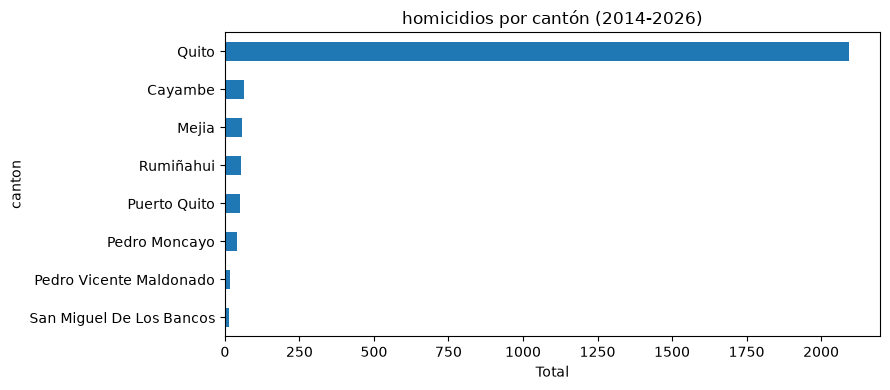

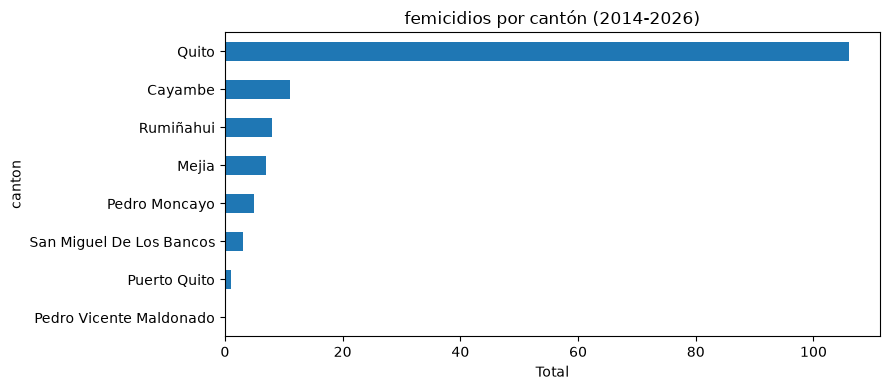

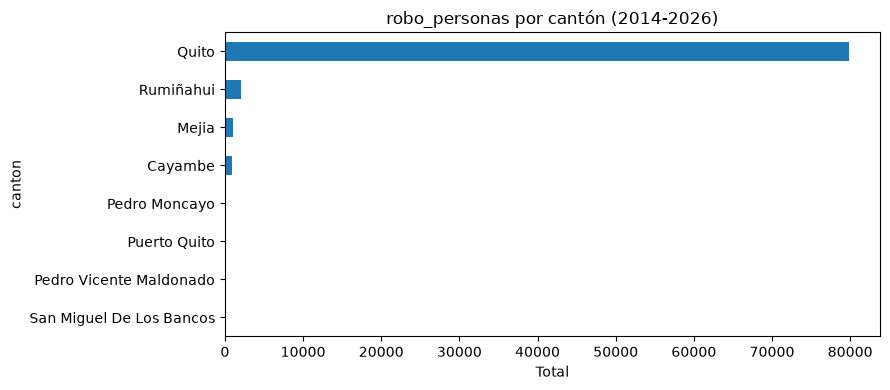

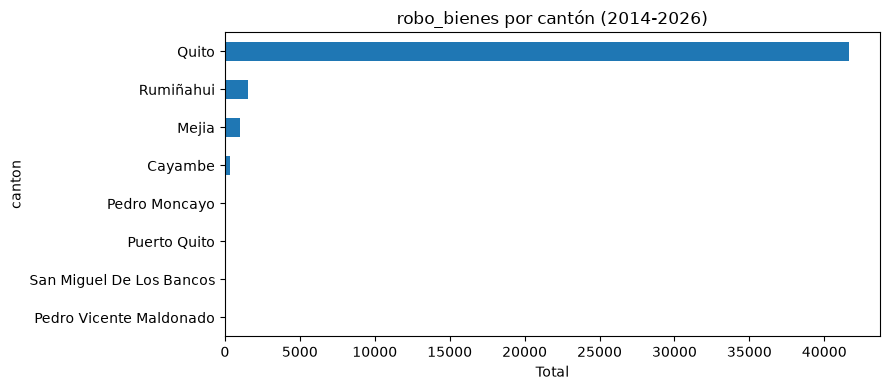

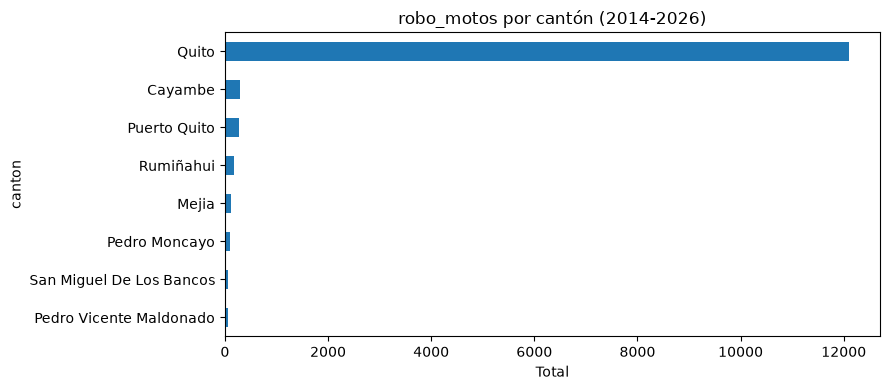

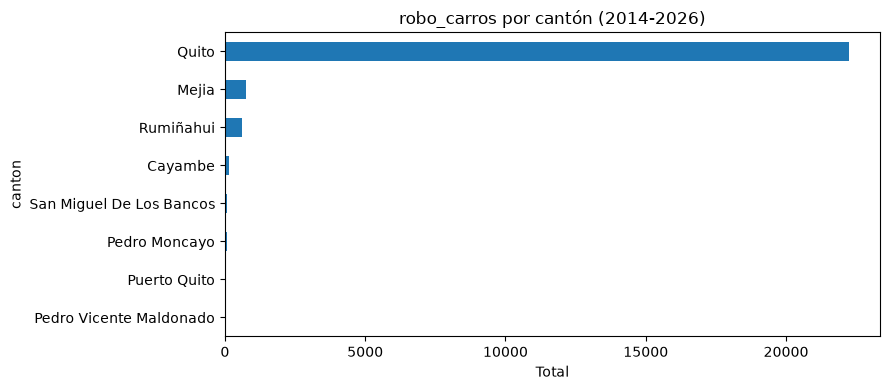

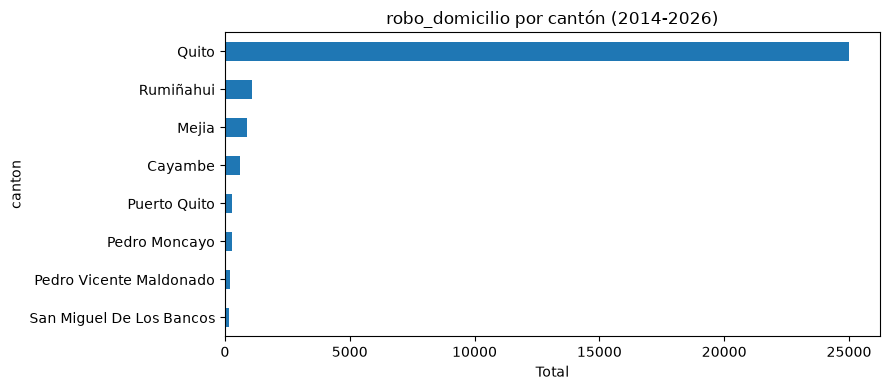

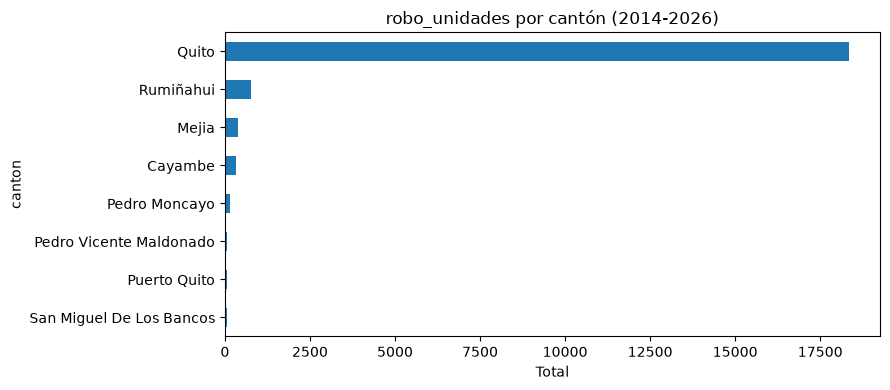

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

tipos = [c for c in cantones.columns
         if c not in ("mes", "codigo_dpa", "canton")]

for col in tipos:
    totales = cantones.groupby("canton")[col].sum().sort_values()
    totales.plot(kind="barh", figsize=(9, 4),
                 title=f"{col} por cantón (2014-2026)")
    plt.xlabel("Total")
    plt.tight_layout(); plt.show()


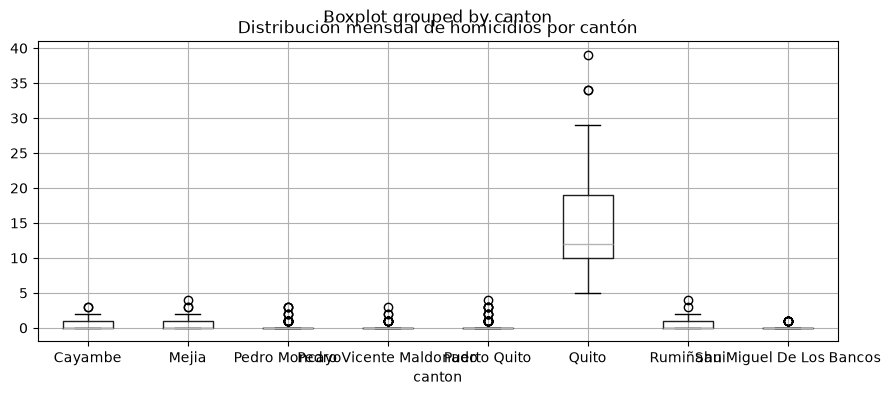

In [55]:
cantones.boxplot(column="homicidios", by="canton", figsize=(10, 4))
plt.title("Distribución mensual de homicidios por cantón"); plt.show()

In [58]:
cantones.describe()

,codigo_dpa,homicidios,femicidios,robo_personas,robo_bienes,robo_motos,robo_carros,robo_domicilio,robo_unidades
count,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000
mean,1704.875000,2.042808,0.120719,72.167808,38.264555,11.243151,20.514555,24.386130,17.274829
std,2.713979,5.250524,0.432187,183.562833,100.289202,28.430811,52.490794,64.676009,42.841058
min,1701.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1702.750000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,1704.500000,0.000000,0.000000,3.000000,1.000000,1.000000,1.000000,3.000000,1.000000
75%,1707.250000,1.000000,0.000000,11.000000,8.000000,2.000000,5.000000,7.000000,4.000000
max,1709.000000,39.000000,4.000000,795.000000,553.000000,133.000000,254.000000,423.000000,234.000000


##Limpiando las columnas

cantones.columns.tolist()

## 1. Convertir Excel a CSV
Una hoja = un CSV:

In [13]:
for hoja in pd.ExcelFile(XLSX).sheet_names:
    df = pd.read_excel(XLSX, sheet_name=hoja)
    destino = CSV_DIR / f"{hoja.strip().replace(' ', '_')}.csv"
    df.to_csv(destino, index=False, encoding='utf-8')
    print(f"{destino.name}: {df.shape[0]} filas x {df.shape[1]} columnas")

Guía.csv: 8 filas x 2 columnas
Provincia.csv: 146 filas x 10 columnas
Cantones.csv: 1168 filas x 12 columnas
Glosario.csv: 12 filas x 2 columnas


## 2. Explorar los datos

In [14]:
provincia = pd.read_csv(CSV_DIR / 'Provincia.csv', parse_dates=['Mes'])
cantones = pd.read_csv(CSV_DIR / 'Cantones.csv', parse_dates=['Mes'])
print('Cobertura temporal:', provincia['Mes'].min().date(), '->', provincia['Mes'].max().date())
print('Cantones de Pichincha:', cantones['Cantón'].unique().tolist())
provincia.head()

Cobertura temporal: 2014-01-01 -> 2026-02-01
Cantones de Pichincha: ['Quito', 'Cayambe', 'Mejia', 'Pedro Moncayo', 'Rumiñahui', 'San Miguel De Los Bancos', 'Pedro Vicente Maldonado', 'Puerto Quito']


,Mes,Provincia,Homicidios intencionales,Femicidios,Denuncias: robo a personas,"Denuncias: robo de bienes, accesorios y autopartes de vehículos",Denuncias: robo de motos,Denuncias: robo de carros,Denuncias: robo a domicilio,Denuncias: robo a unidades económicas
0,2014-01-01,Pichincha,10,0,776,506,71,194,358,224
1,2014-02-01,Pichincha,15,1,637,438,48,140,293,198
2,2014-03-01,Pichincha,14,0,677,521,40,166,336,192
3,2014-04-01,Pichincha,18,0,599,500,57,170,303,184
4,2014-05-01,Pichincha,23,0,719,592,55,196,305,177


In [15]:
cantones.groupby('Cantón')['Homicidios intencionales'].sum().sort_values(ascending=False)

Cantón
Quito                       2093
Cayambe                       63
Mejia                         57
Rumiñahui                     53
Puerto Quito                  49
Pedro Moncayo                 39
Pedro Vicente Maldonado       18
San Miguel De Los Bancos      14
Name: Homicidios intencionales, dtype: int64

## 3. Vista rápida de la tendencia

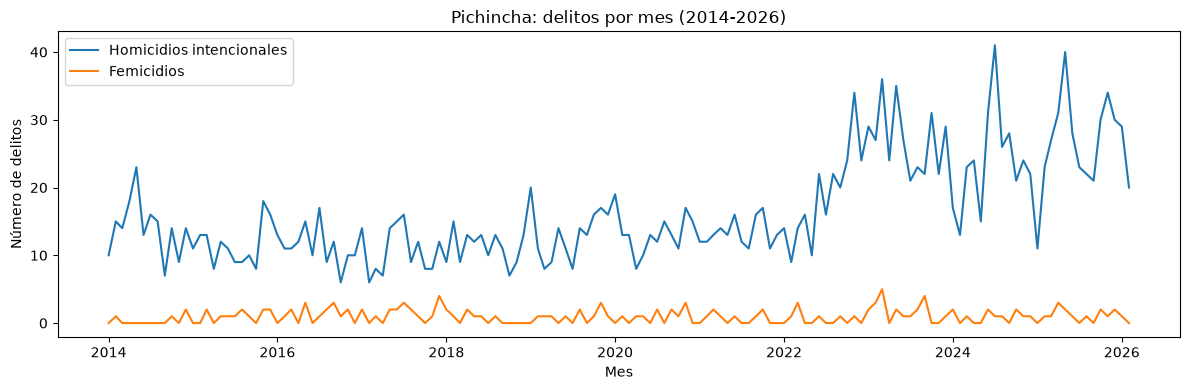

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(provincia['Mes'], provincia['Homicidios intencionales'], label='Homicidios intencionales')
ax.plot(provincia['Mes'], provincia['Femicidios'], label='Femicidios')
ax.set_title('Pichincha: delitos por mes (2014-2026)')
ax.set_xlabel('Mes'); ax.set_ylabel('Número de delitos'); ax.legend()
plt.tight_layout(); plt.show()